# Exchange-Rate Fair Value: Purchasing Power Parity, Real Exchange Rates and Balassa-Samuelson for Thirty Currencies, a Behavioural Equilibrium Exchange Rate and Its Misalignments, and Whether Fundamentals Beat the Random Walk

What is a currency "worth"? The CFA curriculum's economics readings give the classical answers:

- **Absolute purchasing power parity:** the exchange rate equals the ratio of price levels, so a basket costs the same everywhere.
- **Relative PPP:** the exchange rate changes by the inflation differential, $\%\Delta S \approx \pi_{\text{foreign}} - \pi_{\text{US}}$.
- **The real exchange rate**, the nominal rate adjusted for relative prices, should therefore be stable in the long run, though its deviations are large and slow to die out.

Richer countries have systematically higher price levels (the **Balassa–Samuelson** effect), so fair value must allow for productivity. A **behavioural equilibrium exchange rate (BEER)** models the real rate on such fundamentals and treats the residual as **misalignment**.

This notebook estimates all of these for about thirty currencies against the U.S. dollar, 1990–2024:

1. **Relative PPP** over 1, 5 and 10 years: the slope of exchange-rate changes on inflation differentials.
2. **Price levels and Balassa–Samuelson:** each country's price level relative to the U.S. against its relative income.
3. **A panel BEER:** the real exchange rate on relative productivity, accumulated current accounts and openness; misalignments by country and year.
4. **Mean reversion:** the half-life of misalignments.
5. **Forecasts:** next-year and three-year changes in the dollar exchange rate, out of time (trained to 2010, tested 2011–2024): random walk, PPP reversion, ridge regression and LightGBM. Can anything beat the random walk (Meese and Rogoff, 1983)?

**Data.** World Bank World Development Indicators (official exchange rates, PPP conversion factors, CPI, GDP per capita, current account, trade openness).

**Methods.** Relative and absolute PPP tests, Balassa–Samuelson regression, panel BEER with country effects, AR(1) half-lives, ridge regression, LightGBM, out-of-time evaluation against a random walk (RMSE, direction accuracy).

**Key output.** How well PPP holds by horizon, today's misalignments against the dollar (including the Colombian peso), their half-life, and whether fundamentals forecast exchange rates.

## 1. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
from sklearn.linear_model import Ridge

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
WB_URL = "https://api.worldbank.org/v2/country/{}/indicator/{}"
COUNTRIES = {
    "COL": "Colombia",
    "MEX": "Mexico",
    "BRA": "Brazil",
    "CHL": "Chile",
    "PER": "Peru",
    "ARG": "Argentina",
    "EMU": "Euro area",
    "GBR": "United Kingdom",
    "JPN": "Japan",
    "CHE": "Switzerland",
    "CAN": "Canada",
    "AUS": "Australia",
    "NZL": "New Zealand",
    "NOR": "Norway",
    "SWE": "Sweden",
    "DNK": "Denmark",
    "POL": "Poland",
    "CZE": "Czechia",
    "HUN": "Hungary",
    "TUR": "Turkiye",
    "ZAF": "South Africa",
    "IND": "India",
    "IDN": "Indonesia",
    "KOR": "Korea",
    "THA": "Thailand",
    "MYS": "Malaysia",
    "PHL": "Philippines",
    "CHN": "China",
    "ISR": "Israel",
    "SGP": "Singapore",
    "EGY": "Egypt",
    "USA": "United States",
}
IND = {
    "PA.NUS.FCRF": "fx",
    "PA.NUS.PPP": "ppp",
    "FP.CPI.TOTL": "cpi",
    "NY.GDP.PCAP.PP.KD": "gdp_pc_ppp",
    "BN.CAB.XOKA.GD.ZS": "ca_gdp",
    "NE.TRD.GNFS.ZS": "openness",
    "NY.GDP.MKTP.CD": "gdp_usd",
}
FIRST, LAST = 1990, 2024
TRAIN_LAST = 2010

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-11-12


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 2. Data

Exchange rates are annual averages in local currency per U.S. dollar. The euro area has no official exchange-rate series in the World Bank data and drops out, leaving 30 currencies. The **price level** is the PPP conversion factor divided by the market exchange rate: above 1, the country is more expensive than the United States. The **real exchange rate** is the price level itself (a rise is a real appreciation). Net foreign assets are proxied by the current account balance accumulated since 1990, in % of GDP.

In [3]:
def fetch_wdi():
    out = []
    iso = ";".join(COUNTRIES)
    for code_, name in IND.items():
        r = requests.get(
            WB_URL.format(iso, code_),
            params={
                "format": "json",
                "date": f"{FIRST}:{LAST}",
                "per_page": 20000,
            },
            timeout=120,
        ).json()
        out.append(
            pd.DataFrame([
                {
                    "iso": x["countryiso3code"],
                    "year": int(x["date"]),
                    name: x["value"],
                }
                for x in r[1]
            ]).set_index(["iso", "year"])
        )
    return pd.concat(out, axis=1).reset_index()


W = cached("wdi_fx_fundamentals", fetch_wdi, max_age_hours=24 * 30)
W = W.sort_values(["iso", "year"])
us = W[W.iso == "USA"].set_index("year")
P = W[W.iso != "USA"].copy()
P["country"] = P.iso.map(COUNTRIES)
P["us_cpi"] = P.year.map(us.cpi)
P["us_gdp_pc"] = P.year.map(us.gdp_pc_ppp)
P["price_level"] = P.ppp / P.fx
# real exchange rate (higher = more expensive)
P["log_rer"] = np.log(P.price_level)
P["rel_income"] = np.log(P.gdp_pc_ppp / P.us_gdp_pc)
# accumulated current account, % of GDP / 10
P["nfa"] = (
    P.groupby("iso").ca_gdp.transform(lambda s: s.fillna(0).cumsum()) / 10
)
P["infl_diff"] = np.log(P.cpi / P.groupby("iso").cpi.shift(1)) - np.log(
    P.us_cpi / P.groupby("iso").us_cpi.shift(1)
)
P["dlog_fx"] = P.groupby("iso").fx.transform(lambda s: np.log(s).diff())
P = P.dropna(subset=["fx", "ppp"])
cov = P.groupby("country").agg(
    first=("year", "min"),
    last=("year", "max"),
    years=("year", "size"),
    price_level_latest=("price_level", "last"),
)
print(
    f"{P.iso.nunique()} currencies, {P.year.min()}–{P.year.max()}, {len(P):,}"
    " country-years"
)
cov.sort_values("price_level_latest").round(2)

30 currencies, 1990–2024, 1,047 country-years


,first,last,years,price_level_latest
country,,,,
Egypt,1990,2024,35,0.14
India,1990,2024,35,0.24
Thailand,1990,2024,35,0.30
Indonesia,1990,2024,35,0.30
Malaysia,1990,2024,35,0.31
Philippines,1990,2024,35,0.34
Turkiye,1990,2024,35,0.35
Colombia,1990,2024,35,0.35
South Africa,1990,2024,35,0.40


## 3. Relative PPP by horizon

For every country and non-overlapping window of $h$ years, the change in the log exchange rate (local currency per dollar) is regressed on the cumulative inflation differential. Relative PPP predicts a slope of 1. The test is run on all countries and on the low-inflation ones (average differential below 5% a year).

In [4]:
def ppp_test(h, sub=None):
    rows = []
    for iso, g in P.groupby("iso"):
        g = g.set_index("year").sort_index()
        yrs = list(range(g.index.min(), g.index.max() - h + 1, h))
        for y0 in yrs:
            if y0 + h not in g.index or y0 not in g.index:
                continue
            dfx = np.log(g.at[y0 + h, "fx"] / g.at[y0, "fx"])
            dpi = np.log(g.at[y0 + h, "cpi"] / g.at[y0, "cpi"]) - np.log(
                g.at[y0 + h, "us_cpi"] / g.at[y0, "us_cpi"]
            )
            rows.append((iso, y0, dfx, dpi))
    d = pd.DataFrame(rows, columns=["iso", "y0", "dfx", "dpi"]).dropna()
    if sub is not None:
        d = d[d.iso.isin(sub)]
    X = np.c_[np.ones(len(d)), d.dpi]
    b, res, *_ = np.linalg.lstsq(X, d.dfx, rcond=None)
    r2 = 1 - ((d.dfx - X @ b) ** 2).sum() / ((d.dfx - d.dfx.mean()) ** 2).sum()
    return {
        "windows": len(d),
        "slope": b[1],
        "intercept, % a year": b[0] / h * 100,
        "R²": r2,
    }


avg_diff = P.groupby("iso").infl_diff.mean()
low = avg_diff[avg_diff < 0.05].index
PPP = pd.DataFrame({
    f"{h}-year, {lab}": ppp_test(h, sub)
    for h in (1, 5, 10)
    for lab, sub in [("all", None), ("low inflation", low)]
}).T
print(
    f"Low-inflation countries (average differential < 5% a year): {len(low)}"
    f" of {P.iso.nunique()}"
)
PPP.round(3)

Low-inflation countries (average differential < 5% a year): 20 of 30


,windows,slope,"intercept, % a year",R²
"1-year, all",983.00,0.98,0.69,0.80
"1-year, low inflation",677.00,0.96,0.81,0.11
"5-year, all",174.00,0.97,0.49,0.94
"5-year, low inflation",120.00,0.86,0.57,0.22
"10-year, all",87.00,1.01,0.33,0.95
"10-year, low inflation",60.00,1.05,0.44,0.42


## 4. Price levels, Balassa–Samuelson and a panel BEER

First the cross-country **Balassa–Samuelson** relation: the log price level on log income relative to the U.S. Then a **BEER** for the real exchange rate with country effects (each country has its own long-run level), estimated on 1990–2024:

$$\log RER_{i,t} = \alpha_i + \beta_1\,\text{rel. income}_{i,t} + \beta_2\,NFA_{i,t} + \beta_3\,\text{openness}_{i,t} + \varepsilon_{i,t}$$

Terms of trade, the fourth usual BEER fundamental, are left out because the World Bank series starts only in the 2000s; including them would cut the sample in half.

The residual $\varepsilon_{i,t}$ is the **misalignment**: positive means overvalued against fundamentals.

In [5]:
B = P.dropna(subset=["log_rer", "rel_income"]).copy()
X = np.c_[np.ones(len(B)), B.rel_income]
bs, *_ = np.linalg.lstsq(X, B.log_rer, rcond=None)
B["bs_fit"] = X @ bs
r2_bs = (
    1
    - ((B.log_rer - B.bs_fit) ** 2).sum()
    / ((B.log_rer - B.log_rer.mean()) ** 2).sum()
)

F = B.dropna(subset=["openness", "nfa"]).copy()
F["openness_s"] = F.openness / 100
Xv = ["rel_income", "nfa", "openness_s"]
# within transformation (country effects)
dm = F.groupby("iso")[["log_rer"] + Xv].transform(lambda s: s - s.mean())
beta, *_ = np.linalg.lstsq(dm[Xv].values, dm.log_rer.values, rcond=None)
alpha = F.groupby("iso").apply(
    lambda g: g.log_rer.mean() - g[Xv].mean().values @ beta,
    include_groups=False,
)
F["beer"] = F.iso.map(alpha) + F[Xv].values @ beta
F["misalignment"] = F.log_rer - F.beer
r2_within = (
    1
    - ((dm.log_rer - dm[Xv].values @ beta) ** 2).sum() / (dm.log_rer**2).sum()
)
COEF = pd.Series(
    beta,
    index=[
        "relative income (log)",
        "net foreign assets (10% of GDP)",
        "openness (share of GDP)",
    ],
    name="BEER coefficient",
)
print(
    f"Balassa–Samuelson: log price level = {bs[0]:.2f} + {bs[1]:.2f} × log"
    f" relative income, R² = {r2_bs:.2f} ({len(B):,} country-years)"
)
print(
    f"BEER with country effects: within R² = {r2_within:.2f} ({len(F):,}"
    " country-years)"
)
display(COEF.round(3))
lastyr = F.groupby("iso").year.transform("max") == F.year
MIS = (
    F[lastyr]
    .set_index("country")[["year", "price_level", "misalignment"]]
    .assign(
        misalignment=lambda t: (np.exp(t.misalignment) - 1) * 100,
        bs_gap=lambda t: (
            np.exp(
                B.set_index("country")
                .loc[t.index]
                .groupby(level=0)
                .last()
                .eval("log_rer - bs_fit")
            )
            - 1
        )
        * 100,
    )
)
MIS.columns = [
    "year",
    "price level vs U.S.",
    "BEER misalignment, %",
    "Balassa–Samuelson gap, %",
]
MIS.sort_values("BEER misalignment, %").round(2)

Balassa–Samuelson: log price level = -0.04 + 0.55 × log relative income, R² = 0.65 (1,047 country-years)
BEER with country effects: within R² = 0.22 (1,041 country-years)


relative income (log)              0.47
net foreign assets (10% of GDP)   -0.01
openness (share of GDP)           -0.28
Name: BEER coefficient, dtype: float64

,year,price level vs U.S.,"BEER misalignment, %","Balassa–Samuelson gap, %"
country,,,,
Egypt,2024,0.14,-42.42,-67.44
Japan,2024,0.62,-37.53,-16.39
Turkiye,2024,0.35,-32.64,-45.23
Chile,2024,0.46,-26.37,-20.86
India,2024,0.24,-26.06,-20.69
Malaysia,2024,0.31,-25.65,-50.92
China,2024,0.49,-24.47,-4.37
Korea,2024,0.59,-22.85,-26.67
Colombia,2024,0.35,-22.23,-20.48


## 5. How fast do misalignments close?

An AR(1) on each country's annual misalignment, $\varepsilon_{t+1} = \rho\,\varepsilon_t + u_{t+1}$, gives a half-life of $\ln 0.5 / \ln \rho$. The literature's "PPP puzzle" (Rogoff, 1996) is a half-life of three to five years for real exchange rates.

In [6]:
hl = []
for c, g in F.groupby("country"):
    e = g.sort_values("year").misalignment
    if len(e) < 12:
        continue
    rho = (
        np.corrcoef(e.values[:-1], e.values[1:])[0, 1]
        * e.values[1:].std()
        / e.values[:-1].std()
    )
    hl.append((c, rho, np.log(0.5) / np.log(rho) if 0 < rho < 1 else np.nan))
HL = pd.DataFrame(
    hl, columns=["country", "rho", "half-life, years"]
).set_index("country")
e = F.sort_values(["iso", "year"])
lag = e.groupby("iso").misalignment.shift(1)
m = lag.notna()
rho_pool = (e.misalignment[m] * lag[m]).sum() / (lag[m] ** 2).sum()
print(
    f"Pooled ρ = {rho_pool:.2f} → half-life"
    f" {np.log(0.5) / np.log(rho_pool):.1f} years; median across countries"
    f" {HL['half-life, years'].median():.1f} years"
)
HL.sort_values("half-life, years").round(2)

Pooled ρ = 0.85 → half-life 4.3 years; median across countries 4.2 years


,rho,"half-life, years"
country,,
Mexico,0.69,1.88
South Africa,0.70,1.95
Singapore,0.71,2.00
Egypt,0.75,2.42
Peru,0.77,2.65
New Zealand,0.77,2.70
China,0.77,2.70
Philippines,0.78,2.79
Sweden,0.79,2.87


## 6. Forecasting the exchange rate

Targets: the change in log local currency per dollar over the next 1 and 3 years (positive = the currency weakens). Information at the end of year $t$:
- the BEER misalignment and the Balassa–Samuelson gap,
- the inflation differential of the last year,
- the exchange rate's change over the last 1 and 3 years,
- the current account in % of GDP.

Forecasts:
- **random walk**: no change;
- **PPP reversion**: the inflation differential (relative PPP) plus closing the misalignment at the pooled rate, $-(1-\rho^h)\,\varepsilon_t$;
- **ridge regression** and **LightGBM** on all inputs.

The BEER is re-estimated on data up to 2010 only, so test-period misalignments use no future information. Models are trained on 1992–2010 and tested on 2011–2024.

In [7]:
Ftr = F[F.year <= TRAIN_LAST].copy()
dm_tr = Ftr.groupby("iso")[["log_rer"] + Xv].transform(lambda s: s - s.mean())
beta_tr, *_ = np.linalg.lstsq(
    dm_tr[Xv].values, dm_tr.log_rer.values, rcond=None
)
alpha_tr = Ftr.groupby("iso").apply(
    lambda g: g.log_rer.mean() - g[Xv].mean().values @ beta_tr,
    include_groups=False,
)
G = F[F.iso.isin(alpha_tr.index)].sort_values(["iso", "year"]).copy()
G["mis_rt"] = G.log_rer - (G.iso.map(alpha_tr) + G[Xv].values @ beta_tr)
lag_tr = G.groupby("iso").mis_rt.shift(1)
mm = lag_tr.notna() & (G.year <= TRAIN_LAST)
rho_tr = (G.mis_rt[mm] * lag_tr[mm]).sum() / (lag_tr[mm] ** 2).sum()
bs_tr = np.polyfit(
    B[B.year <= TRAIN_LAST].rel_income, B[B.year <= TRAIN_LAST].log_rer, 1
)
G["bs_gap"] = G.log_rer - np.polyval(bs_tr, G.rel_income)
g_ = G.groupby("iso")
G["chg1"] = g_.fx.transform(lambda s: np.log(s).diff())
G["chg3"] = g_.fx.transform(lambda s: np.log(s).diff(3))
for h in (1, 3):
    G[f"y{h}"] = g_.fx.transform(lambda s: np.log(s).shift(-h) - np.log(s))
FX = ["mis_rt", "bs_gap", "infl_diff", "chg1", "chg3", "ca_gdp"]
res = []
PRED = {}
for h in (1, 3):
    D = G.dropna(subset=FX + [f"y{h}"])
    tr = D.year <= TRAIN_LAST - h
    te = D.year > TRAIN_LAST
    yte = D.loc[te, f"y{h}"]
    preds = {
        "random walk": np.zeros(te.sum()),
        "PPP reversion": (
            (
                D.loc[te, "infl_diff"] * h
                - (1 - rho_tr**h) * D.loc[te, "mis_rt"]
            ).values
        ),
    }
    mu, sd = D.loc[tr, FX].mean(), D.loc[tr, FX].std()
    preds["ridge"] = (
        Ridge(alpha=5.0)
        .fit((D.loc[tr, FX] - mu) / sd, D.loc[tr, f"y{h}"])
        .predict((D.loc[te, FX] - mu) / sd)
    )
    preds["LightGBM"] = (
        lgb.LGBMRegressor(
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=7,
            min_child_samples=20,
            subsample=0.8,
            subsample_freq=1,
            verbose=-1,
            random_state=SEED,
        )
        .fit(D.loc[tr, FX], D.loc[tr, f"y{h}"])
        .predict(D.loc[te, FX])
    )
    rw = np.sqrt(np.mean(yte**2))
    for k, p in preds.items():
        res.append({
            "horizon": f"{h} year{'s' if h > 1 else ''}",
            "forecast": k,
            "RMSE, %": np.sqrt(np.mean((yte - p) ** 2)) * 100,
            "RMSE vs random walk": np.sqrt(np.mean((yte - p) ** 2)) / rw,
            "direction right, %": (
                np.mean(np.sign(p) == np.sign(yte)) * 100
                if k != "random walk"
                else np.nan
            ),
        })
    PRED[h] = D.loc[te, ["country", "year", f"y{h}"]].assign(
        **{k: v for k, v in preds.items()}
    )
FCAST = pd.DataFrame(res).set_index(["horizon", "forecast"])
print(
    f"Pooled ρ on 1990–{TRAIN_LAST}: {rho_tr:.2f}; test years"
    f" {TRAIN_LAST + 1}–{G.year.max()}"
)
FCAST.round(3)

Pooled ρ on 1990–2010: 0.78; test years 2011–2024


RMSE, %  RMSE vs random walk  direction right, %
horizon forecast                                                       
1 year  random walk      10.03                 1.00                 NaN
        PPP reversion    10.37                 1.03               49.60
        ridge             9.02                 0.90               61.01
        LightGBM         10.43                 1.04               53.85
3 years random walk      23.50                 1.00                 NaN
        PPP reversion    23.30                 0.99               54.23
        ridge            23.28                 0.99               61.44
        LightGBM         25.66                 1.09               59.88

## 7. Charts

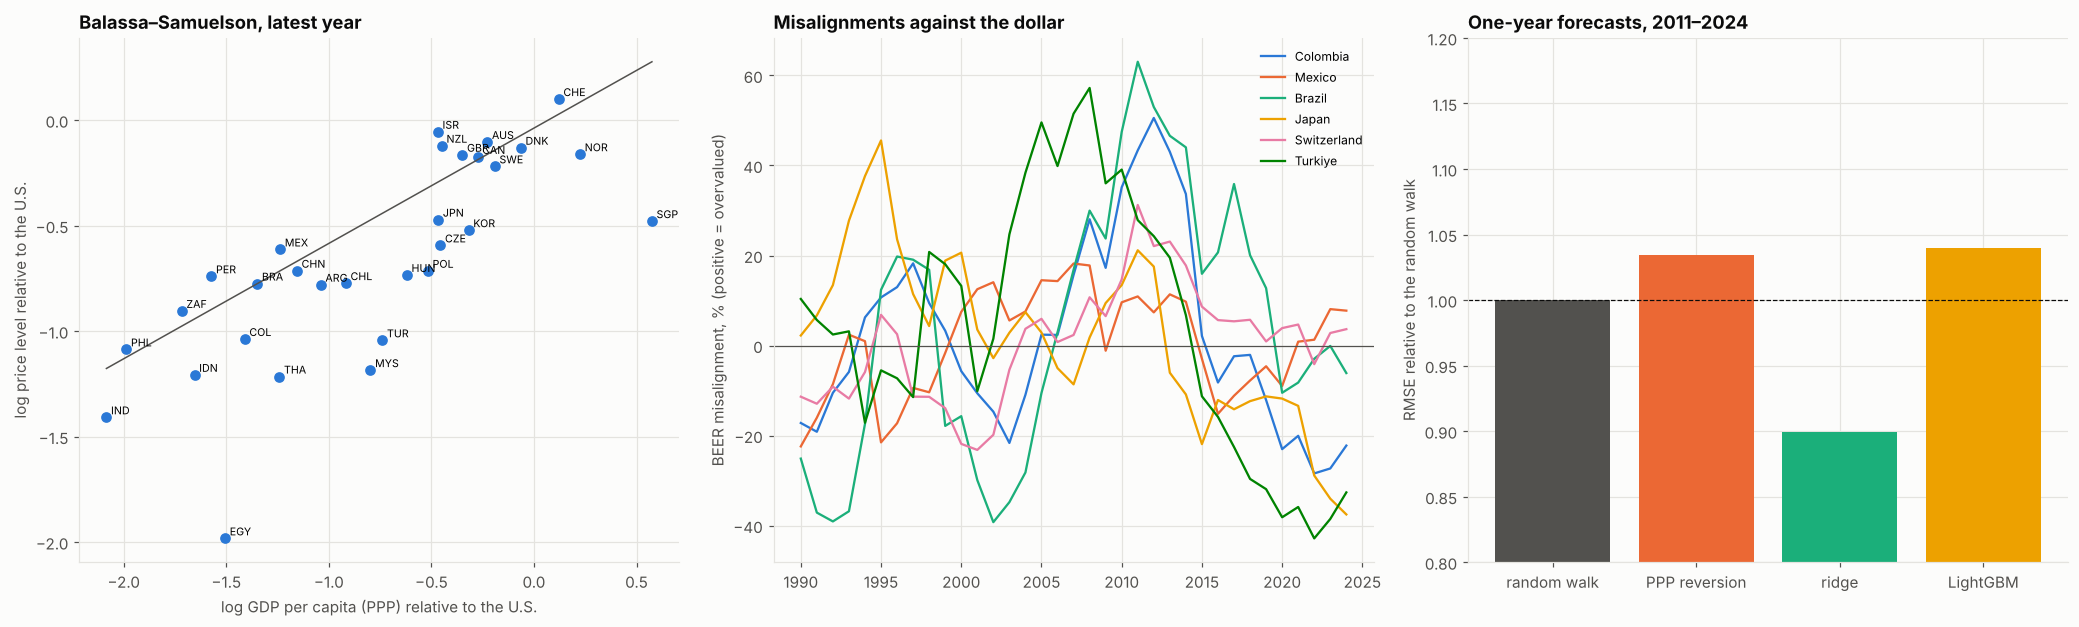

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5.8))
a = ax[0]
lb = B.groupby("iso").last()
a.scatter(lb.rel_income, lb.log_rer, color=PALETTE[0])
for i, r_ in lb.iterrows():
    a.annotate(
        i,
        (r_.rel_income, r_.log_rer),
        fontsize=7,
        xytext=(3, 2),
        textcoords="offset points",
    )
xs = np.linspace(lb.rel_income.min(), lb.rel_income.max(), 50)
a.plot(xs, bs[0] + bs[1] * xs, color=INK_2, lw=1)
a.set_xlabel("log GDP per capita (PPP) relative to the U.S.")
a.set_ylabel("log price level relative to the U.S.")
a.set_title(f"Balassa–Samuelson, latest year")
a = ax[1]
for i, c in enumerate(
    ["Colombia", "Mexico", "Brazil", "Japan", "Switzerland", "Turkiye"]
):
    g = F[F.country == c]
    a.plot(
        g.year,
        (np.exp(g.misalignment) - 1) * 100,
        color=PALETTE[i],
        label=c,
        lw=1.5,
    )
a.axhline(0, color=INK_2, lw=0.8)
a.set_ylabel("BEER misalignment, % (positive = overvalued)")
a.set_title("Misalignments against the dollar")
a.legend(fontsize=8)
a = ax[2]
f1 = FCAST.xs("1 year")
a.bar(f1.index, f1["RMSE vs random walk"], color=[INK_2] + PALETTE[1:4])
a.axhline(1, color=INK, lw=0.8, ls="--")
a.set_ylim(0.8, 1.2)
a.set_ylabel("RMSE relative to the random walk")
a.set_title(f"One-year forecasts, {TRAIN_LAST + 1}–{G.year.max()}")
fig.tight_layout()
save_fig(fig, "01_fx_fair_value")
plt.show()

In [9]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "BEER misalignment, latest year, %",
        "Price level relative to the U.S. over time",
    ),
)
mis = MIS.sort_values("BEER misalignment, %")
dash.add_trace(
    go.Bar(
        x=mis["BEER misalignment, %"],
        y=mis.index,
        orientation="h",
        marker_color=[
            PALETTE[1] if v > 0 else PALETTE[0]
            for v in mis["BEER misalignment, %"]
        ],
        showlegend=False,
    ),
    1,
    1,
)
for i, c in enumerate([
    "Colombia",
    "Brazil",
    "Chile",
    "Mexico",
    "Peru",
    "United Kingdom",
    "Japan",
]):
    g = P[P.country == c]
    dash.add_trace(
        go.Scatter(
            x=g.year,
            y=g.price_level,
            name=c,
            line=dict(color=PALETTE[i % len(PALETTE)]),
        ),
        1,
        2,
    )
dash.update_layout(
    height=760,
    width=1450,
    template="simple_white",
    title="Exchange-rate fair value against the U.S. dollar",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 8. Reading the results and limitations

**The sample.** Thirty currencies have World Bank exchange rates and PPP factors for most of 1990–2024 (1,047 country-years). The euro area drops out for lack of an official series.

**Relative PPP holds on average, and better the longer the horizon.** Regressions of exchange-rate changes on inflation differentials:

| Horizon | All countries: slope (R²) | Low-inflation countries: slope (R²) |
|---|---|---|
| 1 year | 0.98 (0.80) | 0.96 (0.11) |
| 5 years | 0.97 (0.94) | 0.86 (0.22) |
| 10 years | 1.01 (0.95) | 1.05 (0.42) |

The slope is close to 1 at every horizon, as PPP predicts. The fit, however, comes from the high-inflation countries (Argentina, Turkiye, Egypt), whose currencies lose value roughly in step with prices. Among the 20 low-inflation countries, inflation differentials explain only 11% of one-year exchange-rate changes. That share rises to 42% over ten years. For normal currencies, PPP is a long-run anchor, not a guide to next year.

**Richer countries are more expensive (Balassa–Samuelson).** Across countries and years, the log price level rises by 0.55 for each unit of log income relative to the U.S. (R² 0.65). Switzerland, Norway, Denmark, Israel, Australia and New Zealand cost about as much as the United States (price levels 0.9–1.1), while Egypt, India, Indonesia and the Philippines cost 10–30% of U.S. prices.

**The BEER: a model of each country's real exchange rate, and today's misalignments.** With country effects, the real exchange rate rises with relative income (0.47) and falls with openness (−0.28). Accumulated current accounts add almost nothing, and the within-country R² is only 0.22: most year-to-year movement in real exchange rates is not explained by slow-moving fundamentals. Against this BEER, in 2024:
- **Most undervalued:** the Egyptian pound (−42%), Japanese yen (−38%), Turkish lira (−33%), Chilean peso (−26%), Indian rupee (−26%) and Malaysian ringgit (−26%).
- **Colombian peso:** about 22% undervalued, a reading consistent with its simpler Balassa–Samuelson gap of about −20%.
- **Close to fair value or overvalued:** only the Mexican peso (+8%), Czech koruna (+6%) and Swiss franc (+4%).

That almost every currency looks cheap reflects the dollar's own strength in 2022–2024: misalignments here are measured against the dollar, so a strong dollar shows up as undervaluation everywhere.

**Misalignments close slowly: half-lives of about four years.** The pooled AR(1) coefficient is 0.85 (half-life 4.3 years), and the median across countries is 4.2 years, squarely within Rogoff's "PPP puzzle" range of three to five years.
- **Fastest:** Mexico (1.9 years), South Africa and Singapore (2.0).
- **Slowest:** Colombia (6.5), Chile (8.5), Turkiye (12.6) and, above all, Japan (27 years). The yen's real depreciation since 2012 has shown little tendency to reverse.

**Can anything beat the random walk?** Out of time, from 2011 to 2024:

| Horizon | Forecast | RMSE vs random walk | Direction right |
|---|---|---|---|
| 1 year | PPP reversion | 1.03 | 50% |
| 1 year | Ridge | 0.90 | 61% |
| 1 year | LightGBM | 1.04 | 54% |
| 3 years | PPP reversion | 0.99 | 54% |
| 3 years | Ridge | 0.99 | 61% |
| 3 years | LightGBM | 1.09 | 59% |

- **PPP reversion:** inflation differentials plus closing misalignments at the 1990–2010 rate does no better than "no change".
- **Ridge:** a regularised linear model on misalignment, inflation, momentum and the current account cuts the one-year error by 10% and gets the direction right 61% of the time. Consistent with the PPP results, the information is likely concentrated in high-inflation countries, where inflation differentials move exchange rates.
- **LightGBM:** loses to the random walk at both horizons. With about 500 training observations, flexibility costs more than it gains.

Meese and Rogoff's result survives for the most part: fundamentals help a little, and simple models beat complex ones.

**Limits.**
- **Frequency and prices:** annual averages hide intra-year swings, and official rates differ from parallel-market rates where those exist (Argentina, Egypt).
- **Model scope:** the BEER omits terms of trade, interest differentials and fiscal positions.
- **Measurement:** misalignments are against the dollar, not against a trade-weighted basket, because BIS effective exchange rates were not accessible. A trade-weighted view would remove the dollar's own cycle.

In [10]:
PPP.to_csv(OUT_DIR / "relative_ppp_tests.csv")
MIS.to_csv(OUT_DIR / "misalignments_latest.csv")
F[["country", "year", "price_level", "misalignment"]].to_csv(
    OUT_DIR / "beer_misalignments_panel.csv", index=False
)
HL.to_csv(OUT_DIR / "half_lives.csv")
FCAST.to_csv(OUT_DIR / "fx_forecast_test.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_fx_fair_value.png, beer_misalignments_panel.csv, dashboard.html, dashboard.png, fx_forecast_test.csv, half_lives.csv, misalignments_latest.csv, relative_ppp_tests.csv


## References

- World Bank. World Development Indicators API (official exchange rate, PPP conversion factor, CPI, GDP per capita PPP, current account, trade). https://datahelpdesk.worldbank.org/knowledgebase/articles/889392
- CFA Institute. CFA Program Level I curriculum, Economics: Currency Exchange Rates; Level II, Currency Exchange Rates: Understanding Equilibrium Value.
- Rogoff, K. (1996). The purchasing power parity puzzle. *Journal of Economic Literature*, 34(2), 647–668.
- Meese, R. A., & Rogoff, K. (1983). Empirical exchange rate models of the seventies: Do they fit out of sample? *Journal of International Economics*, 14(1–2), 3–24.
- Balassa, B. (1964). The purchasing-power parity doctrine: A reappraisal. *Journal of Political Economy*, 72(6), 584–596.
- Samuelson, P. A. (1964). Theoretical notes on trade problems. *Review of Economics and Statistics*, 46(2), 145–154.
- Clark, P. B., & MacDonald, R. (1999). Exchange rates and economic fundamentals: A methodological comparison of BEERs and FEERs. In *Equilibrium Exchange Rates*, Springer, 285–322.
- Lane, P. R., & Milesi-Ferretti, G. M. (2004). The transfer problem revisited: Net foreign assets and real exchange rates. *Review of Economics and Statistics*, 86(4), 841–857.
- Rossi, B. (2013). Exchange rate predictability. *Journal of Economic Literature*, 51(4), 1063–1119.
- Ke, G., et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems*, 30.